In [16]:
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pymongo import MongoClient

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [17]:
client = MongoClient("mongodb://localhost:27017/")
client.admin.command("ping")

db = client["ev_charging_db"]
db.drop_collection("ev_records")
db.drop_collection("ev_predictions")

ev_records = db["ev_records"]
ev_predictions = db["ev_predictions"]

In [8]:
CSV_PATH = "EV_Charging_Station_Dataset.csv"
records = []

with open(CSV_PATH, newline="", encoding="utf-8") as f:
    for row in csv.DictReader(f):
        records.append({
            "Date": row["Date"],
            "Time": row["Time"],
            "Day_of_Week": row["Day_of_Week"],
            "Is_Weekend": int(row["Is_Weekend"]),
            "City": row["City"],
            "Area": row["Area"],
            "Station_ID": row["Station_ID"],
            "Connector_Type": row["Connector_Type"],
            "Charger_Capacity_kW": int(row["Charger_Capacity_kW"]),
            "Total_Ports": int(row["Total_Ports"]),
            "Active_Plugins": int(row["Active_Plugins"]),
            "Queue_Length": int(row["Queue_Length"]),
            "Avg_Energy_Drawn_kWh": float(row["Avg_Energy_Drawn_kWh"]),
            "Avg_Dwell_Time_Min": int(row["Avg_Dwell_Time_Min"]),
            "Tariff_Rate_INR": float(row["Tariff_Rate_INR"]),
            "Temperature_C": int(row["Temperature_C"]),
            "Weather": row["Weather"],
            "Nearby_Event": int(row["Nearby_Event"]),
            "Station_Status": row["Station_Status"]
        })

if records:
    result = ev_records.insert_many(records)
    print(f"Inserted {len(result.inserted_ids)} records into MongoDB.")

Inserted 450 records into MongoDB.


In [4]:
print("\n--- Retrieving Data & Data Cleaning ---")
data = list(ev_records.find({}, {"_id": 0}))
df = pd.DataFrame(data)

print("Dataset Shape:", df.shape)
print("Missing values per column:\n", df.isnull().sum())
print("Duplicates found:", df.duplicated().sum())

df = df.drop_duplicates()
num_cols = df.select_dtypes(include=np.number).columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())


--- Retrieving Data & Data Cleaning ---
Dataset Shape: (450, 19)
Missing values per column:
 Date                    0
Time                    0
Day_of_Week             0
Is_Weekend              0
City                    0
Area                    0
Station_ID              0
Connector_Type          0
Charger_Capacity_kW     0
Total_Ports             0
Active_Plugins          0
Queue_Length            0
Avg_Energy_Drawn_kWh    0
Avg_Dwell_Time_Min      0
Tariff_Rate_INR         0
Temperature_C           0
Weather                 0
Nearby_Event            0
Station_Status          0
dtype: int64
Duplicates found: 0


In [9]:
df_summary = df.groupby(["City", "Station_Status"]).agg(
    Total_Stations=("Station_ID", "count"),
    Avg_Active_Plugins=("Active_Plugins", "mean"),
    Avg_Energy_Drawn=("Avg_Energy_Drawn_kWh", "mean"),
    Max_Queue=("Queue_Length", "max")
).round(2).reset_index()

print(df_summary.head())

     City   Station_Status  Total_Stations  Avg_Active_Plugins  \
0  Mumbai        Available              61                2.31   
1  Mumbai             Busy              30                6.50   
2  Mumbai  Fully Congested               1                8.00   
3  Nagpur        Available              57                2.88   
4  Nagpur             Busy              42                5.64   

   Avg_Energy_Drawn  Max_Queue  
0             72.75          0  
1            200.87          2  
2            263.07          5  
3             86.56          0  
4            180.69          2  


In [6]:
def get_city_charging_summary():
    pipeline = [
        {
            "$group": {
                "_id": {"City": "$City", "Status": "$Station_Status"},
                "Total_Stations": {"$sum": 1},
                "Avg_Active_Plugins": {"$avg": "$Active_Plugins"},
                "Avg_Energy_Drawn_kWh": {"$avg": "$Avg_Energy_Drawn_kWh"},
                "Max_Queue_Length": {"$max": "$Queue_Length"}
            }
        },
        {
            "$sort": {"_id.City": 1, "Total_Stations": -1}
        },
        {
            "$project": {
                "_id": 0,
                "City": "$_id.City",
                "Status": "$_id.Status",
                "Total_Stations": 1,
                "Avg_Active_Plugins": {"$round": ["$Avg_Active_Plugins", 2]},
                "Avg_Energy_Drawn_kWh": {"$round": ["$Avg_Energy_Drawn_kWh", 2]},
                "Max_Queue_Length": 1
            }
        }
    ]
    
    return list(ev_records.aggregate(pipeline))

Target Class Distribution:
 Available          284
Busy               160
Fully Congested      6
Name: Station_Status, dtype: int64


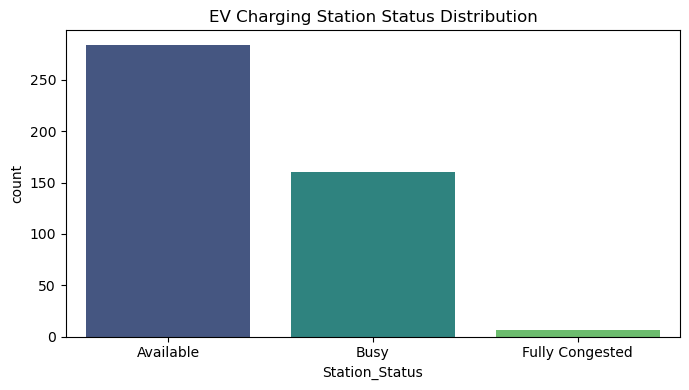

In [10]:
print("Target Class Distribution:\n", df["Station_Status"].value_counts())

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Station_Status", order=["Available", "Busy", "Fully Congested"], palette="viridis")
plt.title("EV Charging Station Status Distribution")
plt.tight_layout()
plt.show()

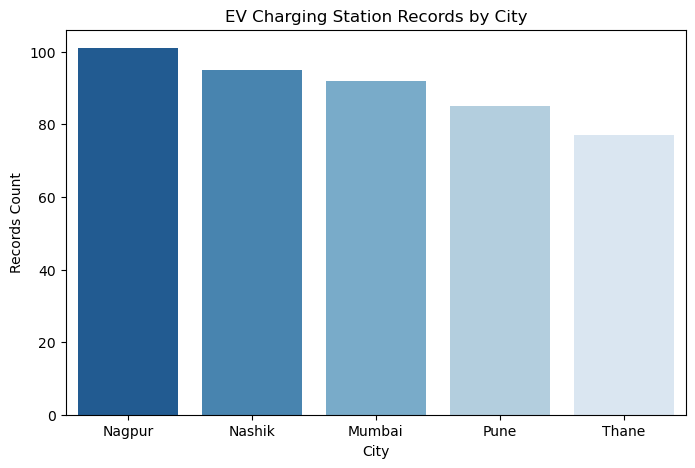

In [18]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="City", order=df["City"].value_counts().index, palette="Blues_r")
plt.title("EV Charging Station Records by City")
plt.xlabel("City")
plt.ylabel("Records Count")
plt.show()

In [12]:
feature_cols = [
    "Is_Weekend", "City", "Connector_Type", "Charger_Capacity_kW", 
    "Total_Ports", "Active_Plugins", "Queue_Length", "Avg_Energy_Drawn_kWh", 
    "Avg_Dwell_Time_Min", "Tariff_Rate_INR", "Temperature_C", "Weather", "Nearby_Event"
]

X = pd.get_dummies(df[feature_cols], columns=["City", "Connector_Type", "Weather"], drop_first=False, dtype=int)
y = df["Station_Status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Train Shape: {X_train.shape}, Test Shape: {X_test.shape}")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Train Shape: (360, 23), Test Shape: (90, 23)


In [13]:

rf_model = RandomForestClassifier(n_estimators=300, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

lr_model = LogisticRegression(max_iter=2000)
lr_model.fit(X_train_scaled, y_train)
lr_preds = lr_model.predict(X_test_scaled)

def evaluate_model(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="macro")
    rec = recall_score(y_true, y_pred, average="macro")
    f1 = f1_score(y_true, y_pred, average="macro")
    print(f"\n[{name} Evaluation]")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-Score : {f1:.4f}")
    print("Confusion Matrix:\n", confusion_matrix(y_true, y_pred, labels=["Available", "Busy", "Fully Congested"]))
    return acc, prec, rec, f1

evaluate_model("Random Forest", y_test, rf_preds)
evaluate_model("Logistic Regression", y_test, lr_preds)



[Random Forest Evaluation]
Accuracy : 0.8778
Precision: 0.5938
Recall   : 0.5671
F1-Score : 0.5750
Confusion Matrix:
 [[56  1  0]
 [ 9 23  0]
 [ 0  1  0]]

[Logistic Regression Evaluation]
Accuracy : 0.9667
Precision: 0.6446
Recall   : 0.6458
F1-Score : 0.6450
Confusion Matrix:
 [[57  0  0]
 [ 2 30  0]
 [ 0  1  0]]


C:\Users\HP\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1469: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\HP\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1469: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


(0.9666666666666667,
 0.6446145434663751,
 0.6458333333333334,
 0.6450465243568692)

In [10]:

importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nTop 5 Most Important Features:\n", importances.head(5))


Top 5 Most Important Features:
 Tariff_Rate_INR         0.222427
Avg_Energy_Drawn_kWh    0.205695
Active_Plugins          0.163725
Queue_Length            0.081297
Total_Ports             0.072016
dtype: float64


In [14]:
pred_docs = []
for actual, pred in zip(y_test, rf_preds):
    pred_docs.append({
        "actual_status": actual,
        "predicted_status": str(pred),
        "is_correct": bool(actual == pred)
    })

res = ev_predictions.insert_many(pred_docs)
print(f"Saved {len(res.inserted_ids)} predictions. Total in collection:", ev_predictions.count_documents({}))

Saved 90 predictions. Total in collection: 90


In [15]:
sample_data = pd.DataFrame([{
    "Is_Weekend": 1,
    "City": "Mumbai",
    "Connector_Type": "CCS2",
    "Charger_Capacity_kW": 120,
    "Total_Ports": 10,
    "Active_Plugins": 9,
    "Queue_Length": 4,
    "Avg_Energy_Drawn_kWh": 280.5,
    "Avg_Dwell_Time_Min": 45,
    "Tariff_Rate_INR": 18.5,
    "Temperature_C": 34,
    "Weather": "Hot/Humid",
    "Nearby_Event": 1
}])

sample_encoded = pd.get_dummies(sample_data, columns=["City", "Connector_Type", "Weather"], drop_first=False, dtype=int)
sample_encoded = sample_encoded.reindex(columns=X.columns, fill_value=0)

predicted_status = rf_model.predict(sample_encoded)[0]
probabilities = rf_model.predict_proba(sample_encoded)[0]

print(f"Predicted Station Status: {predicted_status}")
print("Class Probabilities:")
for cls, prob in zip(rf_model.classes_, probabilities):
    print(f"  - {cls}: {prob:.2%}")

client.close()

Predicted Station Status: Busy
Class Probabilities:
  - Available: 2.00%
  - Busy: 54.67%
  - Fully Congested: 43.33%
